# AMC 2026 – Round 3 · Strategy A: regimes

**Superseded by `03b_strategy_A_backtest.ipynb`**: this notebook's regime table uses the whole sample (look-ahead); 03b picks in real time, with trials and a discount. Not part of the delivery (plan C5).
Matterhorn Capital Management · group 3

The same steps as the TA's notebook (`02_round3_macro_lecture.ipynb`, §2), with two changes:
1. **growth = CFNAI**, 3-month average above 0 (the TA uses the ISM manufacturing PMI above 50);
2. **our SAA asset classes** (the TA uses his example SAA).

The data come from our Bloomberg template → `01_bloomberg_macro_data.ipynb` (`r7_macro.csv`, `r7_extra.csv`, `r7_assets.csv`, `r7_rf_long.csv`).

## 0. Settings

In [1]:
import numpy as np                     # arrays and matrix algebra
import pandas as pd                    # tables with dates
import matplotlib.pyplot as plt        # plots
pd.set_option("display.float_format", "{:.4f}".format)

# Our SAA of Round 1 (data/holdings.json)
W_SAA = pd.Series({"VTI": 0.1090, "VEA": 0.1024, "IEMG": 0.1023, "BND": 0.1333,
                   "BNDX": 0.1648, "TIP": 0.1526, "GLD": 0.1115, "BCI": 0.1240})

## 1. Strategy A – regimes: which asset class wins in which environment?
**The idea (Class 7):** demand shocks move growth and inflation in the **same** direction, supply shocks in **opposite** directions. This gives **four environments**.

**The two signals:**
- growth: CFNAI (Chicago Fed National Activity Index: 85 monthly indicators of US production, jobs, consumption and orders; 0 = growth at its long-run trend), 3-month average. Above 0 = growth above trend;
- inflation: CPI year-on-year (% change in US consumer prices vs 12 months earlier). Rising = higher than 12 months earlier.

$$g_t = \mathbb{1}\{CFNAI^{3m}_t > 0\}, \qquad \iota_t = \mathbb{1}\{\pi_t > \pi_{t-12}\}$$

Why CFNAI and not the ISM PMI: it covers the whole economy, not only manufacturing; its zero line is trend growth by construction; it is the index of the Class 7 exercise. Why the 3-month average: the monthly value changes sign every 2–3 months (noise); the 3-month average is the Chicago Fed's own summary (CFNAI-MA3), and it turns within a quarter, as a one-month position needs.

| | Inflation falling | Inflation rising |
|---|---|---|
| **Growth up** | Goldilocks | Overheating |
| **Growth down** | Slowdown | Stagflation |

⚠️ **Avoid look-ahead bias:** since CFNAI and CPI are published with a delay, we use the previous month's data to identify the regime and evaluate next-month returns.

Each month, growth is 'up' if the CFNAI 3-month average is above 0 and inflation is 'rising' if CPI y/y is above its value 12 months earlier;
the two together give the environment.

Jan 1991 - Oct 2026: 430 months. Months in each environment:
Goldilocks      95
Overheating    114
Stagflation     86
Slowdown       135

TODAY (latest prints, October 2026): STAGFLATION
  CFNAI, 3-month average: -0.05  -> below 0
  US CPI inflation, y/y (CPI): 3.7% vs 3.0% a year earlier -> rising


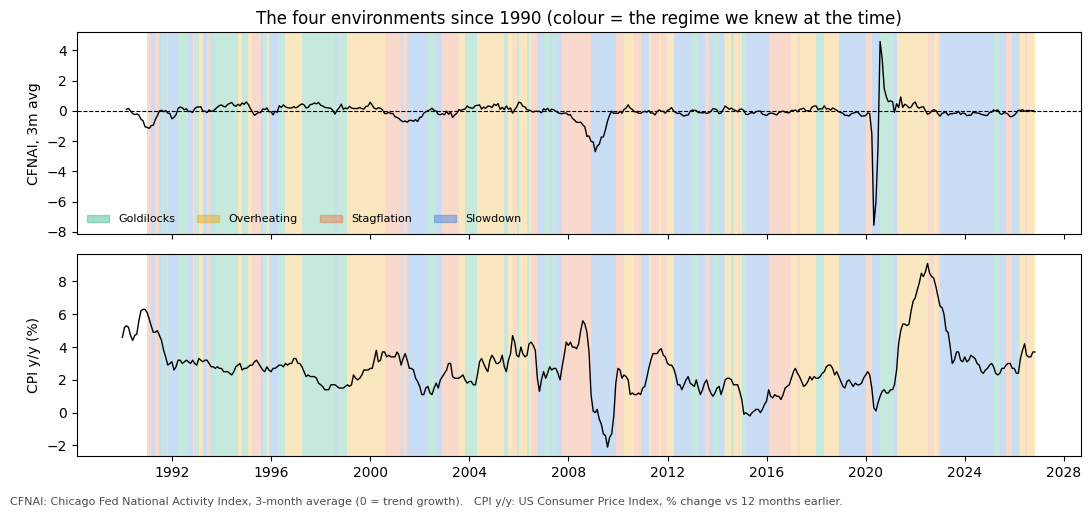

In [2]:
macro  = pd.read_csv("r7_macro.csv", index_col=0, parse_dates=True)
extra  = pd.read_csv("r7_extra.csv", index_col=0, parse_dates=True)        # CFNAI (Extra sheet of our Bloomberg template)
assets = pd.read_csv("r7_assets.csv", index_col=0, parse_dates=True).rename(columns={"DBC": "BCI"})  # BCOMTR = index of our BCI
rf     = pd.read_csv("r7_rf_long.csv", index_col=0, parse_dates=True)["rf"]

macro["CFNAI_3m"] = extra["CFNAI"].rolling(3).mean()           # 3-month average, as the Chicago Fed's CFNAI-MA3
sig    = macro[["CFNAI_3m", "CPI_yoy"]].shift(1)                 # what we know at the end of month t
growth = sig["CFNAI_3m"] > 0
infl   = sig["CPI_yoy"] > sig["CPI_yoy"].shift(12)
known  = sig["CFNAI_3m"].notna() & sig["CPI_yoy"].shift(12).notna()
regime = pd.Series(np.select([growth & ~infl, growth & infl, ~growth & infl, ~growth & ~infl],
                             ["Goldilocks", "Overheating", "Stagflation", "Slowdown"], "?"), index=macro.index)[known]
ORDER  = ["Goldilocks", "Overheating", "Stagflation", "Slowdown"]
COL    = {"Goldilocks": "#1baf7a", "Overheating": "#eda100", "Stagflation": "#eb6834", "Slowdown": "#2a78d6"}

print("Each month, growth is 'up' if the CFNAI 3-month average is above 0 and inflation is 'rising' if CPI y/y is above its value "
      "12 months earlier;\nthe two together give the environment.\n")
print(f"{regime.index[0]:%b %Y} - {regime.index[-1]:%b %Y}: {len(regime)} months. Months in each environment:")
print(regime.value_counts().reindex(ORDER).to_string())
# today: the latest prints we have (published before the trade date)
g_now, cpi_now, cpi_12 = macro["CFNAI_3m"].iloc[-1], macro["CPI_yoy"].iloc[-1], macro["CPI_yoy"].iloc[-13]
today = {(True, False): "Goldilocks", (True, True): "Overheating", (False, True): "Stagflation",
         (False, False): "Slowdown"}[(g_now > 0, cpi_now > cpi_12)]
print(f"\nTODAY (latest prints, {macro.index[-1]:%B %Y}): {today.upper()}")
print(f"  CFNAI, 3-month average: {g_now:.2f}  -> {'above' if g_now > 0 else 'below'} 0")
print(f"  US CPI inflation, y/y (CPI): {cpi_now:.1f}% vs {cpi_12:.1f}% a year earlier -> "
      f"{'rising' if cpi_now > cpi_12 else 'falling'}")

fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
for d, k in regime.items():                                    # one coloured band per month
    for a in ax:
        a.axvspan(d - pd.offsets.MonthEnd(1), d, color=COL[k], alpha=0.25, lw=0)
ax[0].plot(macro["CFNAI_3m"], color="k", lw=1); ax[0].axhline(0, color="k", ls="--", lw=0.8); ax[0].set_ylabel("CFNAI, 3m avg")
ax[1].plot(macro["CPI_yoy"], color="k", lw=1); ax[1].set_ylabel("CPI y/y (%)")
ax[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COL[k], alpha=0.4) for k in ORDER], labels=ORDER,
             ncol=4, loc="lower left", fontsize=8, frameon=False)
ax[0].set_title("The four environments since 1990 (colour = the regime we knew at the time)")
fig.text(0.01, -0.02, "CFNAI: Chicago Fed National Activity Index, 3-month average (0 = trend growth).   "
         "CPI y/y: US Consumer Price Index, % change vs 12 months earlier.", fontsize=8, color="0.3")
plt.tight_layout(); plt.show()

### Which asset class wins in each environment?
For each SAA asset class $j$ and each environment $k$: average excess return of the **following** month (we only know the environment at the end of the month, so month $t+1$ is the first we can trade) and its Sharpe Ratio:

$$\hat\mu_{j,k} = \frac{1}{N_k}\sum_{t:\,s_t = k} R^e_{j,t+1}, \qquad SR_{j,k} = \frac{\hat\mu_{j,k}}{\hat\sigma_{j,k}}\sqrt{12}, \qquad t_{j,k} = SR_{j,k}\sqrt{N_k/12}$$

$N_k$ = number of months in environment $k$. The returns are those of the indices our ETFs track (`r7_assets.csv`): Russell 3000 (VTI), MSCI World ex USA (VEA), MSCI Emerging Markets (IEMG, from 1999), US Aggregate (BND), Global Aggregate hedged in USD (BNDX), US TIPS (TIP), gold (GLD), Bloomberg Commodity (BCI).

In [3]:
NAMES = {"VTI": "US stocks", "VEA": "Developed stocks ex US", "IEMG": "Emerging stocks", "BND": "US bonds",
         "BNDX": "Global bonds (hedged)", "TIP": "TIPS", "GLD": "Gold", "BCI": "Commodities"}   # plain names instead of tickers
Re  = assets[list(W_SAA.index)].pct_change(fill_method=None).sub(rf, axis=0).rename(columns=NAMES)   # monthly excess returns
nxt = Re.shift(-1).loc[regime.index]                              # return of month t+1, next to the regime of month t
g   = nxt.groupby(regime)
SR  = (g.mean() / g.std() * np.sqrt(12)).reindex(ORDER)
N   = g.count().reindex(ORDER)
tst = SR * np.sqrt(N / 12)

print("Annualised Sharpe ratio in the month after each environment (rows = environment, columns = asset class)")
display(SR.style.format("{:.2f}").background_gradient(cmap="RdYlGn", axis=None, vmin=-1.5, vmax=1.5))

best = SR.idxmax(axis=1)
print("Best asset class in each environment (Sharpe, t-stat, months):")
for k in ORDER:
    b = best[k]
    print(f"  {k:12s} -> {b}: Sharpe {SR.loc[k, b]:.2f}, t = {tst.loc[k, b]:.1f}, {N.loc[k, b]} months"
          + ("" if abs(tst.loc[k, b]) > 2 else "   <- not significant: only a weak hint"))

Annualised Sharpe ratio in the month after each environment (rows = environment, columns = asset class)


,US stocks,Developed stocks ex US,Emerging stocks,US bonds,Global bonds (hedged),TIPS,Gold,Commodities
Goldilocks,0.58,0.47,0.54,0.71,0.98,0.40,-0.68,-0.01
Overheating,0.63,0.70,0.73,0.31,0.47,0.50,0.27,0.56
Stagflation,-0.06,-0.48,-0.42,0.71,0.75,0.32,0.40,-0.35
Slowdown,1.20,0.55,0.84,0.44,0.63,0.56,0.88,0.36


Best asset class in each environment (Sharpe, t-stat, months):
  Goldilocks   -> Global bonds (hedged): Sharpe 0.98, t = 2.8, 95 months
  Overheating  -> Emerging stocks: Sharpe 0.73, t = 2.1, 98 months
  Stagflation  -> Global bonds (hedged): Sharpe 0.75, t = 2.0, 86 months
  Slowdown     -> US stocks: Sharpe 1.20, t = 4.0, 135 months


In [4]:
ETF = {"VTI": "Vanguard Total Stock Market ETF", "VEA": "Vanguard FTSE Developed Markets ETF",
       "IEMG": "iShares Core MSCI Emerging Markets ETF", "BND": "Vanguard Total Bond Market ETF",
       "BNDX": "Vanguard Total International Bond ETF", "TIP": "iShares TIPS Bond ETF", "GLD": "SPDR Gold Shares",
       "BCI": "abrdn Bloomberg All Commodity Strategy K-1 Free ETF"}
TICK = {v: k for k, v in NAMES.items()}                           # plain name -> ticker
lab  = lambda a: f"{ETF[TICK.get(a, a)]} ({TICK.get(a, a)})"
hi, lo = best[today], SR.loc[today].idxmin()

print(f"According to our method, today we are in {today.upper()}.")
print(f"  Historically, the best asset class of our SAA in this environment was {lab(hi)}, Sharpe {SR.loc[today, hi]:.2f} "
      f"(t = {tst.loc[today, hi]:.1f}, {N.loc[today, hi]} months);")
print(f"  the worst was {lab(lo)}, Sharpe {SR.loc[today, lo]:.2f}.")
print(f"-> the macro strategy buys {TICK.get(hi, hi)} on top of the SAA (overweight relative to the SAA).")

According to our method, today we are in STAGFLATION.
  Historically, the best asset class of our SAA in this environment was Vanguard Total International Bond ETF (BNDX), Sharpe 0.75 (t = 2.0, 86 months);
  the worst was Vanguard FTSE Developed Markets ETF (VEA), Sharpe -0.48.
-> the macro strategy buys BNDX on top of the SAA (overweight relative to the SAA).


## 2. Invest
The position is the ETF printed above. Its size comes from the tracking-error budget (TE ≤ 7% for the Round 2 stocks we keep, the quant sleeve and this macro sleeve together): TA notebook 02, §5 (size) and §6 (shares and trades at the close of Friday 27 November).